# Лабораторная работа №1: регрессия

Датасет: [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) из UCI Machine Learning Repository. Работаю только с красными винами (`winequality-red.csv`). По физико-химическим характеристикам вина нужно предсказать его оценку `quality`, которую выставили эксперты (целое число по шкале от 0 до 10).

Основная метрика — RMSE, дополнительная — MAE. Порог по заданию: RMSE < 0.70.

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import warnings
warnings.simplefilter("ignore")
%matplotlib inline

sns.set_theme(style="darkgrid")

RANDOM_STATE = 42

# Часть 1. Загружаем данные

Данные по красному вину лежат на UCI в отдельном csv-файле (разделитель `;`).

In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
data = pd.read_csv(url, sep=";")

print(data.shape)
data.head()

(1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


Пропусков нет, все 11 признаков — числовые физико-химические измерения, поэтому заполнять пропуски и кодировать категории не нужно. Целевая переменная `quality` — целое число, но решаем задачу регрессии, т.е. модель предсказывает вещественное число.

Отдельно проверю дубликаты.

In [4]:
features_only = list(data.columns.drop("quality"))

print("Полных дубликатов строк:", data.duplicated().sum())
print("Дубликатов только по признакам (без quality):", data[features_only].duplicated().sum())
print("Групп с одинаковыми признаками, но разной оценкой:", (data.groupby(features_only)["quality"].nunique() > 1).sum())

# насколько далеко друг от друга копии стоят в исходном файле
dups = data[data.duplicated(keep=False)].reset_index()
span = dups.groupby(list(data.columns))["index"].agg(lambda s: s.max() - s.min())
print("Медианное расстояние между копиями = %d строк, доля случаев, когда копии в пределах 5 строк = %.2f" % (span.median(), (span <= 5).mean()))

Полных дубликатов строк: 240
Дубликатов только по признакам (без quality): 240
Групп с одинаковыми признаками, но разной оценкой: 0
Медианное расстояние между копиями = 2 строк, доля случаев, когда копии в пределах 5 строк = 0.92


Получается, что 15% строк (240 из 1599) — точные копии других строк. При этом:
- нет ни одного случая, когда у вин с одинаковыми 11 измерениями разная оценка;
- копии в исходном файле обычно стоят рядом (в 92% случаев в пределах 5 строк друг от друга);
- у признаков десятки и сотни разных значений, так что разным винам случайно совпасть сразу по всем 11 измерениям очень маловероятно.

Скорее всего, это повторные записи одного и того же вина (например, несколько бутылок одной партии), а не разные вина с одинаковыми характеристиками. Но проверить это точно нельзя — в описании датасета на UCI я про это ничего не нашёл.

Удалять их я не стал: это наблюдения из исходного датасета, и скрытая тестовая выборка, скорее всего, тоже содержит такие повторы. Но надо помнить о последствиях: если одна копия попала в train, а другая в test (или в разные фолды кросс-валидации), то для модели это уже «знакомый» объект, и оценка качества получается оптимистичной. Насколько сильно — проверю в анализе ошибок (часть 11).

Если нужен вариант без дубликатов, достаточно раскомментировать строку в ячейке ниже и перезапустить весь ноутбук.

In [5]:
# вариант без дубликатов: раскомментировать строку ниже и перезапустить ноутбук
# data = data.drop_duplicates().reset_index(drop=True)

print(data.shape)

(1599, 12)


# Часть 2. Подготовка выборок

Делю данные на train и test **до** исследовательского анализа. Всё, что я дальше смотрю (распределения, корреляции), смотрю только на train, чтобы выводы и выбор признаков/моделей никак не зависели от ответов тестовой выборки.

In [6]:
from sklearn.model_selection import train_test_split

y = data["quality"]
X = data.drop(columns=["quality"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Train:", X_train.shape, " Test:", X_test.shape)
pd.DataFrame({
    "train, шт": y_train.value_counts(),
    "test, шт": y_test.value_counts(),
    "train, доля": y_train.value_counts(normalize=True),
    "test, доля": y_test.value_counts(normalize=True),
}).sort_index().round(4)

Train: (1279, 11)  Test: (320, 11)


,"train, шт","test, шт","train, доля","test, доля"
quality,,,,
3,8,2,0.0063,0.0062
4,42,11,0.0328,0.0344
5,545,136,0.4261,0.4250
6,510,128,0.3987,0.4000
7,159,40,0.1243,0.1250
8,15,3,0.0117,0.0094


**Размер выборок.** Взял 80% / 20%: 1279 объектов в train и 320 в test. Данных мало (всего 1599 вин), поэтому большую часть оставляю на обучение. 320 объектов в тесте — это немного, оценка RMSE на тесте будет довольно шумной, поэтому все решения принимаю по кросс-валидации на train, а тест нужен только для финальной проверки. Брать тест ещё меньше не хочу: тогда в него попадали бы единицы вин с редкими оценками.

**Способ разбиения.** Случайное разбиение со стратификацией по `quality`. Оценки сильно несбалансированы: вин с оценкой 3 всего 10, с оценкой 8 — 18. При обычном случайном разбиении в тест могло бы не попасть ни одного вина с оценкой 3, или, наоборот, попасть сразу много, и тестовый RMSE сильно зависел бы от удачи. Стратификация сохраняет доли каждой оценки одинаковыми в train и test (это видно в таблице выше). `random_state` зафиксирован, поэтому разбиение воспроизводится.

**Почему нельзя много раз оценивать модели на одной и той же тестовой выборке.** Если подбирать модель, признаки или гиперпараметры, каждый раз проверяя результат на тесте, то тест фактически становится частью обучения: я выберу то, что случайно хорошо сработало именно на этих 320 объектах. Получится переобучение под тестовую выборку, и оценка на ней станет оптимистичной, т.е. перестанет показывать качество на действительно новых данных. При маленьком тесте это особенно опасно: случайные колебания RMSE на нём большие, и «выбрать лучшее по тесту» легко. Поэтому все решения я принимаю по кросс-валидации на train, а тест использую только в конце для финального сравнения моделей.

# Часть 3. Знакомство с данными

Весь анализ в этой части — только по обучающей выборке.

quality
3    0.006
4    0.033
5    0.426
6    0.399
7    0.124
8    0.012
Name: proportion, dtype: float64
Среднее = 5.637, медиана = 6.0, std = 0.809


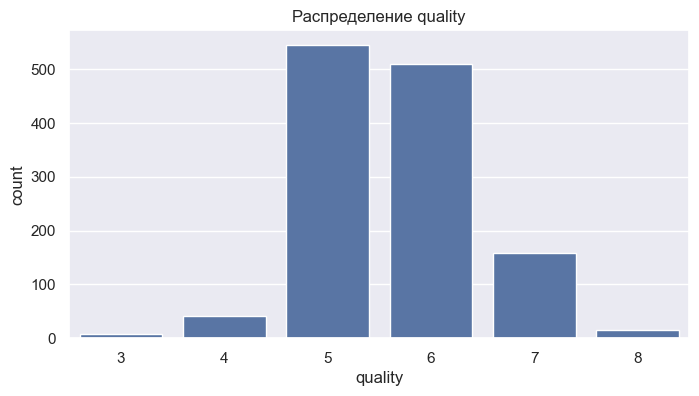

In [7]:
train = X_train.copy()
train["quality"] = y_train

plot = sns.countplot(x=y_train, color="C0")
plot.figure.set_size_inches(8, 4)
plt.title("Распределение quality")

print(y_train.value_counts(normalize=True).sort_index().round(3))
print("Среднее = %.3f, медиана = %.1f, std = %.3f" % (y_train.mean(), y_train.median(), y_train.std()))

Выводы:
- Оценки сильно сконцентрированы в центре: на 5 и 6 приходится ~83% всех вин, а крайние оценки 3, 4 и 8 вместе — около 5% (с оценкой 3 в train всего 8 вин, с оценкой 8 — 15). Значит, даже константа ≈ 5.6 будет в среднем ошибаться меньше чем на балл, а предсказывать крайние оценки моделям будет трудно: примеров мало, и функция потерь (MSE) в основном «тянет» модель к центру.
- Реально используется только шкала 3–8: оценок 0–2, 9 и 10 у красных вин нет вообще, т.е. совсем плохих и идеальных вин модель никогда не увидит.
- `quality` — целое число (порядковая шкала), а регрессия будет выдавать вещественные числа, например 5.6. Для RMSE это нормально: для вина, которое «между» 5 и 6, предсказание 5.6 в среднем даёт меньшую ошибку, чем жёсткий выбор одного из вариантов.

In [8]:
train.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1279.0,8.306,1.695,4.600,7.100,7.900,9.300,15.900
volatile acidity,1279.0,0.528,0.178,0.120,0.395,0.520,0.635,1.580
citric acid,1279.0,0.274,0.195,0.000,0.100,0.260,0.430,1.000
residual sugar,1279.0,2.544,1.376,0.900,1.900,2.200,2.600,15.400
chlorides,1279.0,0.089,0.051,0.012,0.070,0.080,0.091,0.611
free sulfur dioxide,1279.0,16.128,10.474,1.000,7.000,14.000,22.000,68.000
total sulfur dioxide,1279.0,47.281,33.335,6.000,22.000,39.000,64.000,289.000
density,1279.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,1279.0,3.309,0.152,2.740,3.210,3.310,3.400,3.900
sulphates,1279.0,0.664,0.178,0.370,0.550,0.620,0.740,2.000


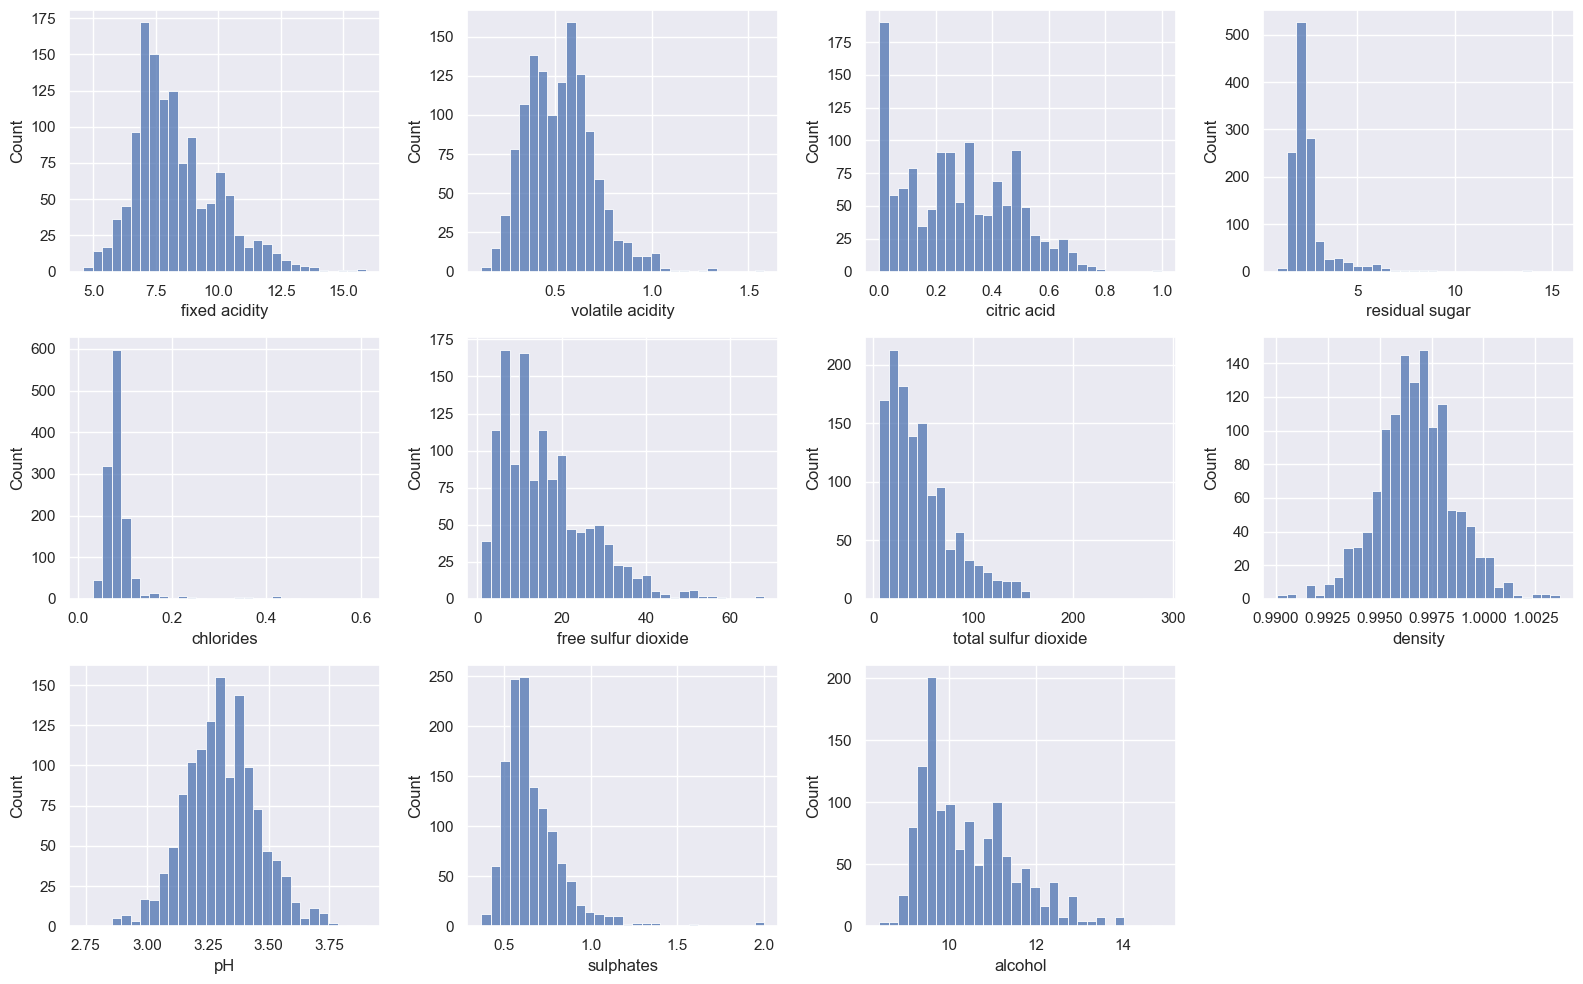

In [9]:
fig, axs = plt.subplots(figsize=(16, 10), nrows=3, ncols=4)
for i, feature in enumerate(X_train.columns):
    sns.histplot(X_train[feature], bins=30, ax=axs[i // 4, i % 4])
axs[2, 3].axis("off")
plt.tight_layout()

Выводы:
- Признаки измерены в совершенно разных масштабах: `density` меняется в третьем знаке после запятой (std = 0.002), а `total sulfur dioxide` — от 6 до 289 (std ≈ 33). Для деревьев это неважно, а вот веса линейной регрессии без масштабирования сравнивать между собой будет нельзя (подробнее в части 6).
- `density` и `pH` распределены почти нормально, а у многих признаков длинный правый хвост и выбросы: `residual sugar` (у 75% вин до 2.6, а максимум 15.4), `chlorides` (75%-квантиль 0.091, максимум 0.611), `total sulfur dioxide` (75%-квантиль 64, максимум 289), `sulphates` (75%-квантиль 0.74, максимум 2.0). Выбросы я не удаляю: это реальные вина, и в тестовой выборке такие тоже могут встретиться. Деревья к выбросам в признаках устойчивы (им важен только порядок значений), а на линейную модель они могут влиять сильнее.
- У `citric acid` заметный пик в нуле — у довольно многих вин лимонной кислоты нет совсем.

Посмотрим, какие признаки сильнее всего линейно связаны с `quality` (корреляция Пирсона).

alcohol                 0.481
sulphates               0.228
citric acid             0.211
fixed acidity           0.108
residual sugar          0.004
free sulfur dioxide    -0.048
pH                     -0.052
chlorides              -0.120
density                -0.193
total sulfur dioxide   -0.195
volatile acidity       -0.383
dtype: float64

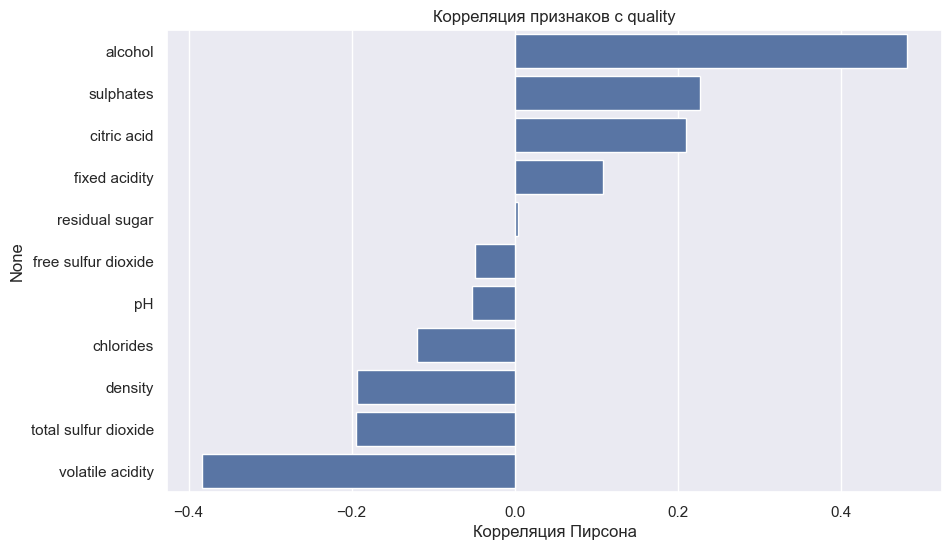

In [10]:
correlations = X_train.corrwith(y_train).sort_values(ascending=False)

plot = sns.barplot(y=correlations.index, x=correlations, color="C0")
plot.figure.set_size_inches(10, 6)
plt.title("Корреляция признаков с quality")
plt.xlabel("Корреляция Пирсона")

correlations.round(3)

Выводы:
- Сильнее всего с качеством связан алкоголь (r ≈ 0.48): чем крепче вино, тем выше оценка. Это главный кандидат в признаки.
- Второй по силе — `volatile acidity` (−0.38). Летучая кислотность — это в основном уксусная кислота, при большом её количестве у вина появляется уксусный привкус, так что связь логичная: это признак дефекта.
- Слабее, но заметно связаны `sulphates` (0.23), `citric acid` (0.21), `total sulfur dioxide` (−0.20) и `density` (−0.19).
- Остальные признаки (`residual sugar`, `free sulfur dioxide`, `pH`) по отдельности почти не связаны с `quality` (|r| ≈ 0–0.05). Это ещё не значит, что они бесполезны: корреляция Пирсона ловит только линейную связь и только одного признака.
- Все корреляции умеренные: ни один признак сам по себе качество не определяет, так что идеального предсказания ждать не стоит.

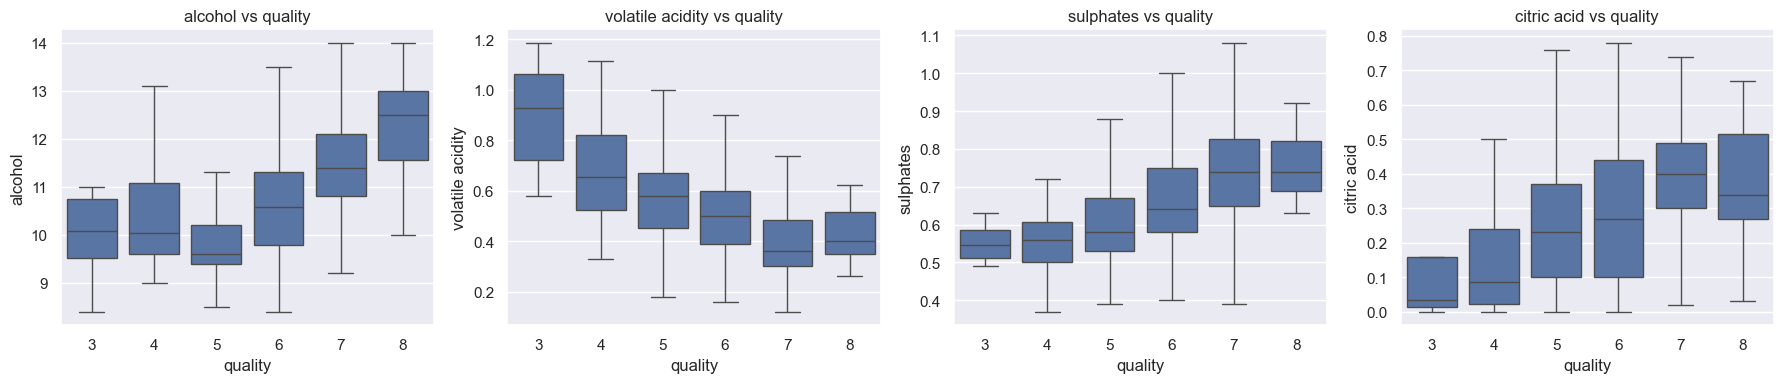

In [11]:
fig, axs = plt.subplots(figsize=(18, 4), ncols=4)
for i, feature in enumerate(["alcohol", "volatile acidity", "sulphates", "citric acid"]):
    sns.boxplot(data=train, x="quality", y=feature, showfliers=False, color="C0", ax=axs[i])
    axs[i].set_title(feature + " vs quality")
plt.tight_layout()

Выводы:
- `alcohol` растёт с оценкой, но нелинейно: для оценок 3–5 медиана алкоголя примерно одинаковая (~10, а у оценки 5 даже чуть ниже), а с 5 начинается уверенный рост (9.6 → 10.6 → 11.4 → 12.5). Линейная модель уловит общий тренд, но не этот «излом».
- `volatile acidity` падает с ростом оценки, но сильнее всего различаются плохие вина: у оценки 3 медиана 0.93, у 5 — 0.58, а у 7 и 8 уже почти одинаково (0.36 и 0.40). Похоже на признак дефекта: высокая летучая кислотность резко снижает оценку, а ниже какого-то уровня уже не важна. Такие пороговые зависимости хорошо ловят деревья.
- `sulphates` растут с оценкой до 7, а дальше выходят на плато (у 7 и 8 медиана одинаковая, 0.74) — тоже нелинейная связь с насыщением.
- `citric acid` растёт от 3 к 7: у самых плохих вин лимонной кислоты почти нет.

Text(0.5, 1.0, 'Корреляции между признаками')

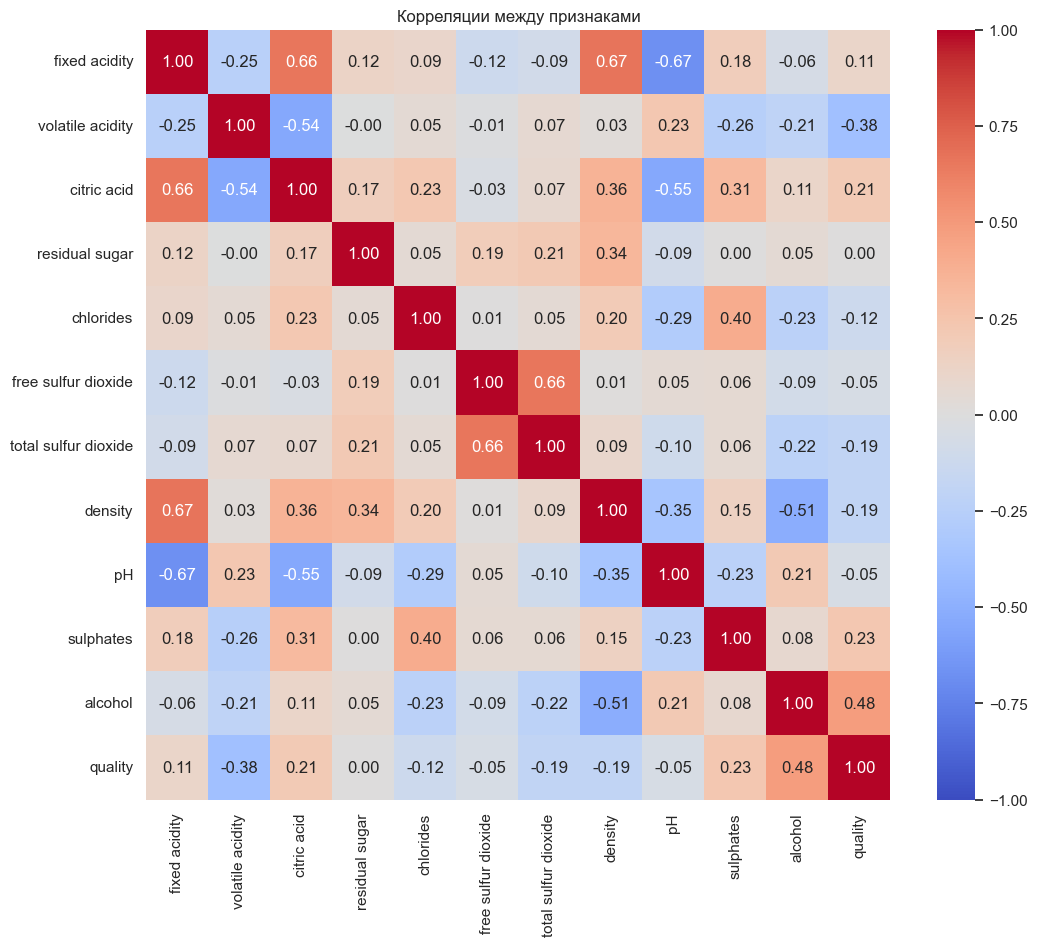

In [12]:
plt.figure(figsize=(12, 10))
sns.heatmap(train.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Корреляции между признаками")

Выводы:
- Есть «кислотный» блок сильно связанных признаков: `fixed acidity` коррелирует с `citric acid` (0.66), `density` (0.67) и `pH` (−0.67), а `citric acid` — с `volatile acidity` (−0.54) и `pH` (−0.55). Это химия: чем больше кислот, тем ниже pH, а растворённые кислоты увеличивают плотность.
- `density` связана с `alcohol` (−0.51): спирт легче воды. Т.е. отрицательная связь плотности с качеством — во многом «отражение» алкоголя.
- `free sulfur dioxide` и `total sulfur dioxide` сильно связаны (0.66): свободный диоксид серы — это часть общего.
- `sulphates` связаны с `chlorides` (0.40).

Получается мультиколлинеарность. Для линейной регрессии это значит, что веса скоррелированных признаков будут неустойчивыми и их нельзя интерпретировать по отдельности (модель может дать большой отрицательный вес одному признаку и положительный другому, так что они друг друга компенсируют). У деревьев скоррелированные признаки будут «делить» между собой важность.

### Что я беру из анализа данных в моделирование
1. Таргет сосредоточен на 5–6, крайние оценки редкие. Ожидаю, что хуже всего модели будут предсказывать 3–4 и 8, это нужно проверить в анализе ошибок.
2. Главные признаки — `alcohol` и `volatile acidity`, дальше `sulphates`, `citric acid`, `total sulfur dioxide`. Ни одна связь не сильная.
3. Часть зависимостей нелинейная (излом у алкоголя, порог у летучей кислотности, насыщение у сульфатов) — поэтому кроме линейной регрессии нужны модели на деревьях.
4. Признаки в разных масштабах и скоррелированы (кислотный блок, плотность и алкоголь, два диоксида серы) — для линейной регрессии нужно масштабирование, а её веса нужно интерпретировать осторожно.
5. Все признаки оставляю: их всего 11, пропусков нет, а слабая линейная корреляция не значит, что признак бесполезен для нелинейной модели.

# Часть 4. Метрики

$$\text{MAE} = \frac{1}{\ell}\sum_{i=1}^{\ell} |y_i - a(x_i)|, \qquad \text{RMSE} = \sqrt{\frac{1}{\ell}\sum_{i=1}^{\ell} (y_i - a(x_i))^2}$$

**Что показывает MAE.** Среднее абсолютное отклонение предсказания от правильного ответа, в тех же единицах, что и `quality` (в баллах). MAE = 0.5 значит, что в среднем модель ошибается на полбалла. Каждая ошибка входит в среднее пропорционально своей величине.

**Что показывает RMSE.** Корень из среднего квадрата ошибки. Тоже измеряется в баллах, но это не «средняя ошибка», а скорее типичный размер ошибки, в котором большие ошибки весят больше. Минимизировать RMSE — то же самое, что минимизировать MSE, а именно MSE по умолчанию оптимизируют линейная регрессия и деревья в sklearn.

**Почему RMSE сильнее реагирует на большие ошибки.** Перед усреднением ошибки возводятся в квадрат. Ошибка в 2 балла даёт вклад 4, а ошибка в 0.5 балла — 0.25, т.е. в 16 раз меньше (в MAE — только в 4 раза). Поэтому одна большая ошибка увеличивает RMSE сильнее, чем много мелких.

**Почему для одной и той же модели MAE и RMSE могут заметно различаться.** Всегда RMSE ≥ MAE (среднее квадратичное не меньше среднего арифметического), и равны они только тогда, когда все ошибки одинаковы по модулю. Чем неоднороднее ошибки, т.е. чем больше среди них редких, но крупных, тем больше разрыв. Так что по отношению RMSE/MAE можно понять, есть ли у модели «выбросы» в ошибках. В этой задаче я этого как раз жду: на типичных винах (5–6) модель будет ошибаться мало, а на редких (3, 4, 8) — сильно.

Для удобства заведу функцию, которая считает обе метрики на тесте и складывает их в общую таблицу результатов (туда же записываю CV RMSE на train).

In [13]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

results = {}

def evaluate(name, y_true, y_pred, cv_rmse=np.nan):
    rmse = root_mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    results[name] = {"RMSE": rmse, "MAE": mae, "CV RMSE": cv_rmse}
    print("%s: Test RMSE = %.4f, Test MAE = %.4f" % (name, rmse, mae))

**Схема валидации.** Все решения (гиперпараметры, выбор лучшей модели) принимаю по кросс-валидации на train: 5 фолдов с перемешиванием и фиксированным `random_state`, один и тот же объект `cv` для всех моделей, чтобы они сравнивались на одинаковых разбиениях. Тест используется только для финальной оценки.

In [14]:
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Часть 5. Baseline

В качестве baseline предсказываю одну константу для всех объектов. Какую константу брать, зависит от метрики:
- для MSE/RMSE оптимальная константа — **среднее** значение таргета: если продифференцировать $\sum_i (y_i - c)^2$ по $c$ и приравнять к нулю, получится $c = \frac{1}{\ell}\sum_i y_i$;
- для MAE оптимальная константа — **медиана**.

Основная метрика — RMSE, поэтому baseline = среднее `quality` по **train** (тест для подсчёта константы не используется).

In [15]:
from sklearn.dummy import DummyRegressor

best_constant = y_train.mean()
print("Best constant (mean of y_train) = %.4f" % best_constant)

cv_scores = cross_val_score(DummyRegressor(strategy="mean"), X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
print("Mean CV RMSE = %.4f" % np.mean(-cv_scores))

y_pred_baseline = best_constant * np.ones(y_test.shape)
evaluate("Baseline", y_test, y_pred_baseline, np.mean(-cv_scores))

# для сравнения: медиана - оптимальная константа для MAE
median_constant = y_train.median()
y_pred_median = median_constant * np.ones(y_test.shape)
print("Median constant = %.1f: Test RMSE = %.4f, Test MAE = %.4f" % (median_constant, root_mean_squared_error(y_test, y_pred_median), mean_absolute_error(y_test, y_pred_median)))

Best constant (mean of y_train) = 5.6372
Mean CV RMSE = 0.8080
Baseline: Test RMSE = 0.8033, Test MAE = 0.6812
Median constant = 6.0: Test RMSE = 0.8839, Test MAE = 0.6562


Вывод: baseline даёт на тесте RMSE = 0.803, на CV — 0.808, это почти ровно стандартное отклонение `quality` (0.809). Так и должно быть: RMSE константы, равной среднему, и есть std таргета. Значит, полезная модель должна давать RMSE заметно меньше 0.80, а порог 0.70 — это примерно на 13% лучше константы.

Медиана (6) даёт RMSE хуже (0.884), но MAE лучше (0.656 против 0.681). Это подтверждает, что для разных метрик оптимальны разные константы. В таблицу записываю среднее, т.к. основная метрика — RMSE.

# Часть 6. Линейная регрессия

Строю `Pipeline` из `StandardScaler` и `LinearRegression`. Pipeline нужен, чтобы при кросс-валидации scaler обучался (считал среднее и std) только на обучающих фолдах, а не на всём train, иначе в обучение протекает информация из валидационного фолда.

Требуется ли масштабирование? На качество обычной линейной регрессии (без регуляризации) масштабирование не влияет: если признак умножить на число, вес просто поделится на это число, и предсказания останутся теми же. Но оно сильно влияет на **интерпретацию коэффициентов**, это разберу ниже.

In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

linear_pipeline = Pipeline([
    ("scaling", StandardScaler()),
    ("regression", LinearRegression())
])

cv_scores = cross_val_score(linear_pipeline, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
print("Cross validation scores:\n\t", "\n\t".join("%.4f" % x for x in -cv_scores))
print("Mean CV RMSE = %.4f" % np.mean(-cv_scores))

linear_pipeline.fit(X_train, y_train)
y_pred_linear = linear_pipeline.predict(X_test)

print("Train RMSE = %.4f" % root_mean_squared_error(y_train, linear_pipeline.predict(X_train)))
evaluate("Linear Regression", y_test, y_pred_linear, np.mean(-cv_scores))

Cross validation scores:
	 0.6418
	0.6907
	0.6228
	0.6990
	0.6304
Mean CV RMSE = 0.6570
Train RMSE = 0.6486
Linear Regression: Test RMSE = 0.6375, Test MAE = 0.4951


Вывод: линейная регрессия даёт CV RMSE = 0.657 и RMSE = 0.638 на тесте (MAE = 0.495). Это на 21% лучше baseline (0.803), т.е. модель действительно извлекает из признаков полезную информацию, и порог 0.70 она проходит.

Ошибка на train (0.649) почти такая же, как на CV, значит переобучения нет. Скорее модель **недообучена**: часть зависимостей нелинейная (излом у алкоголя, порог у летучей кислотности, насыщение у сульфатов), а линейная модель может только сложить признаки с весами. Разброс по фолдам заметный (0.62–0.70): в каждом фолде всего ~256 вин, и ошибка сильно зависит от того, сколько в фолд попало редких оценок. По этой же причине тестовый RMSE (0.638) немного ниже CV — тест из 320 вин получился чуть «проще» среднего.

In [17]:
def show_weights(features, weights, scales, title):
    fig, axs = plt.subplots(figsize=(14, 5), ncols=2)
    sorted_weights = sorted(zip(weights, features, scales), reverse=True)
    weights = [x[0] for x in sorted_weights]
    features = [x[1] for x in sorted_weights]
    scales = [x[2] for x in sorted_weights]
    sns.barplot(y=features, x=weights, color="C0", ax=axs[0])
    axs[0].set_xlabel("Weight")
    axs[0].set_title(title)
    sns.barplot(y=features, x=scales, color="C1", ax=axs[1])
    axs[1].set_xlabel("Scale (std)")
    plt.tight_layout()

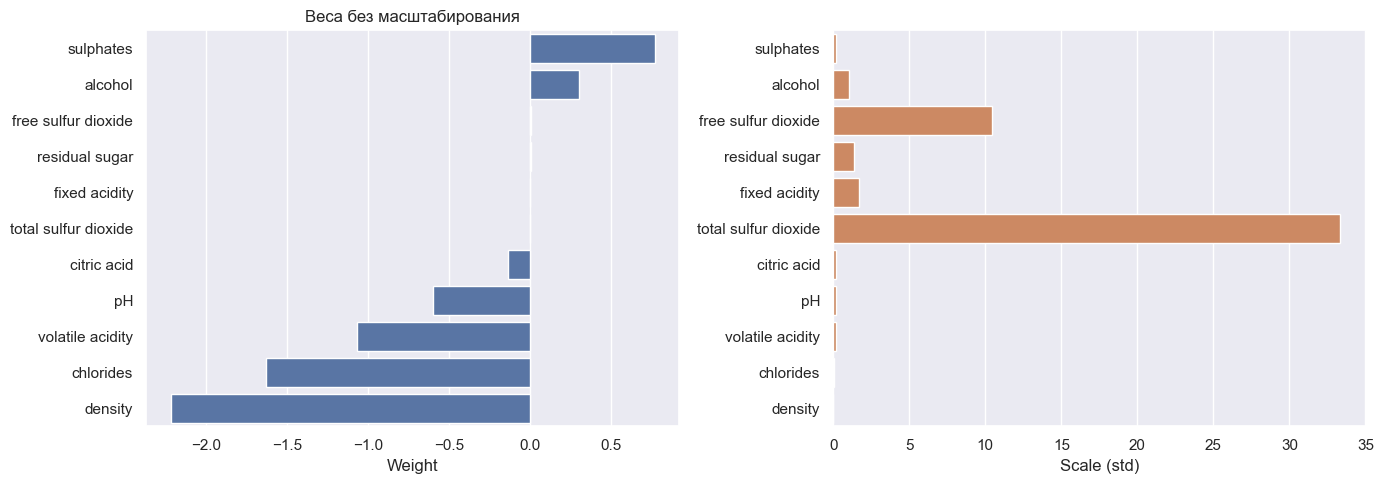

In [18]:
raw_model = LinearRegression().fit(X_train, y_train)
show_weights(X_train.columns, raw_model.coef_, X_train.std(), "Веса без масштабирования")

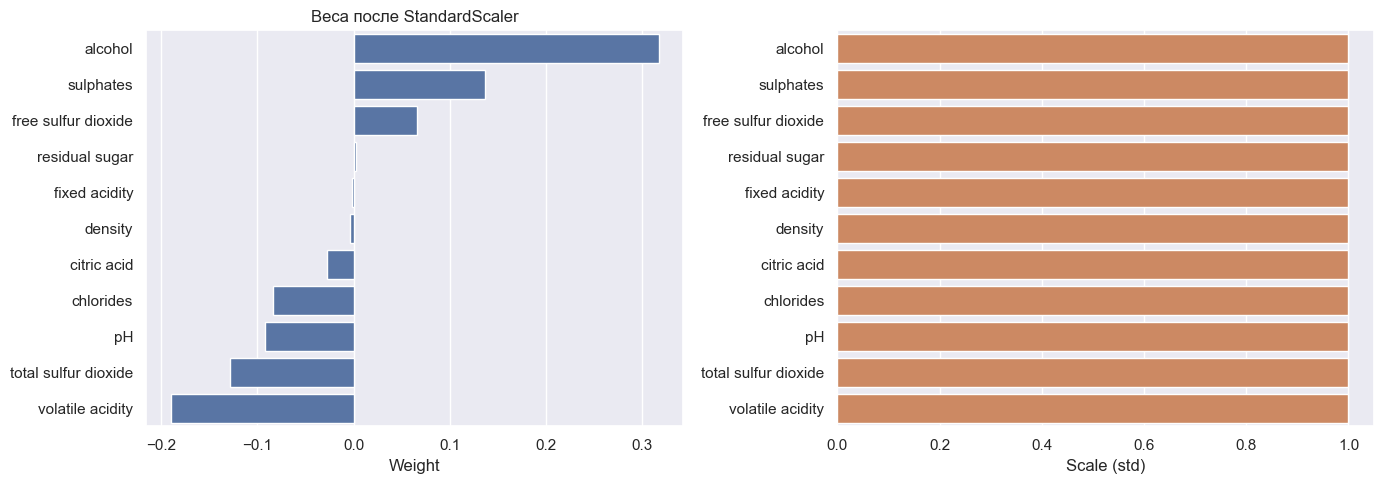

In [19]:
scaler = linear_pipeline.named_steps["scaling"]
linear_model = linear_pipeline.named_steps["regression"]
X_train_scaled = scaler.transform(X_train)

show_weights(X_train.columns, linear_model.coef_, X_train_scaled.std(axis=0), "Веса после StandardScaler")

In [20]:
coefs = pd.DataFrame({
    "вес без масштабирования": raw_model.coef_,
    "std признака": scaler.scale_,
    "вес после масштабирования": linear_model.coef_,
}, index=X_train.columns)
coefs["|вес после масштабирования|"] = coefs["вес после масштабирования"].abs()
coefs.sort_values("|вес после масштабирования|", ascending=False).round(4)

,вес без масштабирования,std признака,вес после масштабирования,|вес после масштабирования|
alcohol,0.2975,1.0653,0.3169,0.3169
volatile acidity,-1.0691,0.1776,-0.1899,0.1899
sulphates,0.7669,0.1783,0.1367,0.1367
total sulfur dioxide,-0.0039,33.3218,-0.1284,0.1284
pH,-0.6043,0.1515,-0.0916,0.0916
chlorides,-1.6351,0.0510,-0.0833,0.0833
free sulfur dioxide,0.0063,10.4695,0.0659,0.0659
citric acid,-0.1405,0.1948,-0.0274,0.0274
density,-2.2214,0.0019,-0.0041,0.0041
residual sugar,0.0020,1.3752,0.0028,0.0028


Выводы по коэффициентам:
- **Без масштабирования** сравнивать веса нельзя. Самые большие по модулю веса у `density` (−2.22) и `chlorides` (−1.64), а у алкоголя всего 0.30. Но плотность меняется в пределах ~0.002, поэтому её реальный вклад в предсказание (вес × std признака) ≈ −2.22 × 0.002 ≈ −0.004 балла, т.е. почти ноль. И наоборот, у `total sulfur dioxide` вес всего −0.004, но сам признак меняется на десятки единиц, и вклад получается заметный.
- **После StandardScaler** вес показывает, на сколько баллов меняется предсказание, если признак увеличить на одно стандартное отклонение (при остальных фиксированных). В таблице видно, что вес после масштабирования = вес до × std признака. Теперь веса можно сравнивать между собой.
- Наибольшее влияние в линейной модели у `alcohol` (+0.32), `volatile acidity` (−0.19), `sulphates` (+0.14) и `total sulfur dioxide` (−0.13). Знаки совпадают с корреляциями из EDA. У `density`, `residual sugar` и `fixed acidity` веса практически нулевые.

Здесь же видна мультиколлинеарность, найденная в EDA:
- `citric acid` коррелирует с качеством (0.21), но его вес почти нулевой (−0.03). Информация о нём уже есть в скоррелированных с ним `volatile acidity`, `sulphates` и `fixed acidity`, и отдельно модели он не нужен.
- То же с `density`: корреляция с качеством −0.19, а вес ≈ 0, потому что её связь с качеством объясняется алкоголем.
- `free sulfur dioxide` получил **положительный** вес (+0.07), хотя его корреляция с качеством около нуля, а у скоррелированного с ним `total sulfur dioxide` вес отрицательный. Модель использует их в паре: «больше свободного SO₂ при том же общем».

Поэтому веса скоррелированных признаков нельзя читать как независимый эффект каждого признака. Надёжные выводы, которые совпадают с EDA: алкоголь и сульфаты повышают предсказание, летучая кислотность и общий диоксид серы понижают.

У `LinearRegression` нет гиперпараметров, которые можно подбирать. Поэтому проверю, не поможет ли регуляризация: подберу `alpha` у `Ridge` случайным поиском по логарифмической шкале с той же кросс-валидацией.

Best alpha = 51.4110
Best CV RMSE = 0.6566


Text(0.5, 1.0, 'Ridge: подбор alpha')

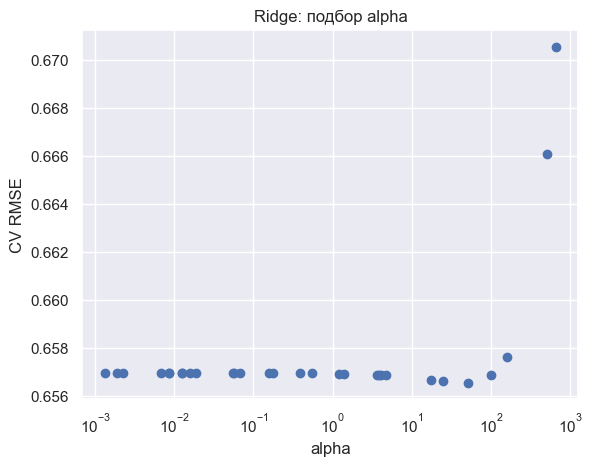

In [21]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform

ridge_pipeline = Pipeline([
    ("scaling", StandardScaler()),
    ("regression", Ridge())
])

ridge_searcher = RandomizedSearchCV(
    ridge_pipeline,
    {"regression__alpha": loguniform(1e-3, 1e3)},
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=RANDOM_STATE
)
ridge_searcher.fit(X_train, y_train)

print("Best alpha = %.4f" % ridge_searcher.best_params_["regression__alpha"])
print("Best CV RMSE = %.4f" % -ridge_searcher.best_score_)

alphas = ridge_searcher.cv_results_["param_regression__alpha"].data.astype(float)
plt.scatter(alphas, -ridge_searcher.cv_results_["mean_test_score"])
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("CV RMSE")
plt.title("Ridge: подбор alpha")

Вывод: регуляризация практически ничего не даёт. CV RMSE почти не меняется при alpha от 0.001 до ~100 (лучшее значение 0.6566 при alpha ≈ 51 против 0.6570 у обычной регрессии), а при большом alpha становится хуже. Это логично: признаков всего 11, объектов больше тысячи, и у модели нет проблемы с переобучением (train ≈ CV), а Ridge борется именно с переобучением. Проблема линейной модели — недообучение, и регуляризацией её не исправить. Поэтому в итоговую таблицу записываю обычную `LinearRegression`, а Ridge на тесте не проверяю (тест не используется для выбора).

# Часть 7. Random Forest

Случайный лес — это усреднение многих глубоких решающих деревьев, каждое из которых обучено на бутстрап-выборке и при каждом разбиении выбирает из случайного подмножества признаков. Деревья умеют находить нелинейные и пороговые зависимости и взаимодействия признаков (например, «высокая летучая кислотность — плохо, если при этом мало сульфатов»), а усреднение уменьшает разброс отдельных деревьев.

Масштабирование для деревьев не нужно: разбиение — это порог вида «признак < t», и при монотонном преобразовании признака меняется только значение порога, а не само разбиение.

Гиперпараметры подбираю через `RandomizedSearchCV` на тех же 5 фолдах:
- `n_estimators` — число деревьев (больше — стабильнее, но дольше);
- `max_depth`, `min_samples_split`, `min_samples_leaf` — ограничивают сложность каждого дерева;
- `max_features` — сколько признаков рассматривать при каждом разбиении (меньше — деревья разнообразнее).

Почему случайный поиск, а не полный перебор по сетке: параметров 5, и полная сетка из всех комбинаций — это тысячи обучений леса. Случайный поиск за фиксированный бюджет (30 комбинаций) пробует больше разных значений каждого параметра, а обычно на качество сильно влияют лишь 1–2 параметра, поэтому этого хватает.

In [22]:
from sklearn.ensemble import RandomForestRegressor
from scipy.stats import randint

rf_params = {
    "n_estimators": randint(100, 600),
    "max_depth": [None, 10, 15, 20, 30],
    "min_samples_split": randint(2, 11),
    "min_samples_leaf": randint(1, 6),
    "max_features": ["sqrt", 0.3, 0.5, 0.7, 1.0],
}

rf_searcher = RandomizedSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE),
    rf_params,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_searcher.fit(X_train, y_train)

print("Best params:", rf_searcher.best_params_)
print("Best CV RMSE = %.4f" % -rf_searcher.best_score_)

Best params: {'max_depth': 15, 'max_features': 0.5, 'min_samples_leaf': 2, 'min_samples_split': 4, 'n_estimators': 463}
Best CV RMSE = 0.5973


In [23]:
rf_cv_results = pd.DataFrame(rf_searcher.cv_results_)
rf_cv_results["CV RMSE"] = -rf_cv_results["mean_test_score"]
rf_cv_results = rf_cv_results.sort_values("CV RMSE")
rf_cv_results[["param_n_estimators", "param_max_depth", "param_min_samples_split", "param_min_samples_leaf", "param_max_features", "CV RMSE", "std_test_score"]].head(10)

,param_n_estimators,param_max_depth,param_min_samples_split,param_min_samples_leaf,param_max_features,CV RMSE,std_test_score
6,463,15,4,2,0.5,0.597316,0.030728
23,200,15,4,1,0.5,0.597389,0.029837
25,162,15,4,2,sqrt,0.597678,0.029242
13,301,30,3,2,0.3,0.598137,0.029841
21,506,20,8,1,0.3,0.598480,0.028539
12,409,20,5,2,0.3,0.598677,0.030128
19,589,15,6,1,0.5,0.599070,0.028874
8,188,30,5,2,sqrt,0.599557,0.029336
17,108,30,8,1,sqrt,0.599751,0.028966
11,149,30,5,1,0.5,0.600428,0.030825


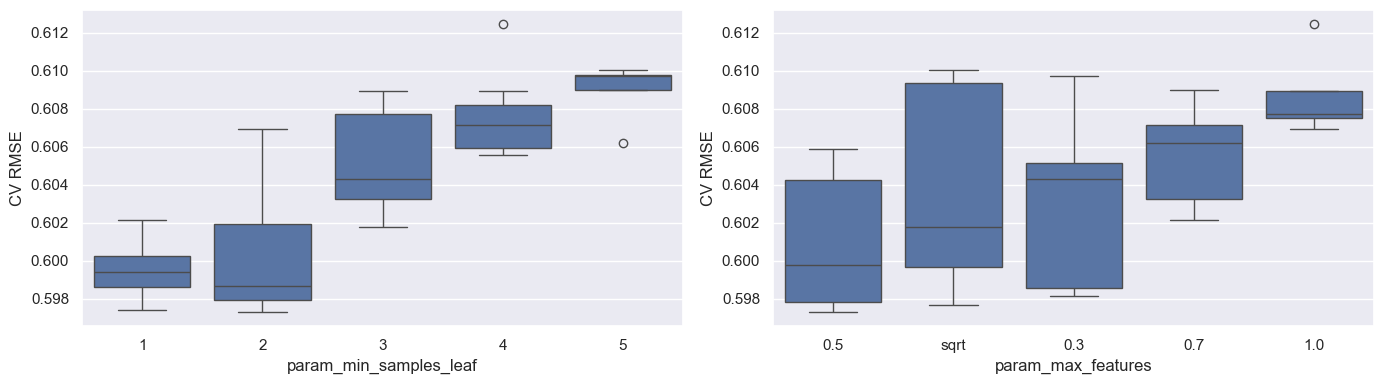

In [24]:
fig, axs = plt.subplots(figsize=(14, 4), ncols=2)
sns.boxplot(data=rf_cv_results, x="param_min_samples_leaf", y="CV RMSE", color="C0", ax=axs[0])
sns.boxplot(data=rf_cv_results, x="param_max_features", y="CV RMSE", color="C0", ax=axs[1])
plt.tight_layout()

In [25]:
rf_model = rf_searcher.best_estimator_
y_pred_rf = rf_model.predict(X_test)

print("Train RMSE = %.4f" % root_mean_squared_error(y_train, rf_model.predict(X_train)))
evaluate("Random Forest", y_test, y_pred_rf, -rf_searcher.best_score_)

Train RMSE = 0.2949
Random Forest: Test RMSE = 0.5697, Test MAE = 0.4271


Вывод:
- Лучшая комбинация: `max_depth=15`, `min_samples_leaf=2`, `min_samples_split=4`, `max_features=0.5`, 463 дерева. CV RMSE = 0.597, на тесте RMSE = 0.570, MAE = 0.427. Порог 0.70 пройден с запасом, ошибка на 29% меньше, чем у baseline.
- По графикам видно, что сильнее всего на качество влияет `min_samples_leaf`: чем меньше листья (т.е. чем точнее дерево подстраивается под отдельные объекты), тем лучше. `max_features` 0.3–0.5 и `sqrt` лучше, чем все признаки (1.0): деревья получаются разнообразнее, и усреднение работает лучше.
- При этом разница между десятью лучшими комбинациями маленькая (0.597–0.600), гораздо меньше разброса по фолдам (std ≈ 0.03). Т.е. точный выбор гиперпараметров здесь почти не важен.
- RMSE на train = 0.29, сильно меньше, чем на тесте. Для случайного леса это нормально (глубокие деревья почти запоминают train). Важно, что оценка на CV честная. То, что выгоднее всего «запоминать» отдельные объекты, отчасти связано с дубликатами: у заметной части объектов валидационного фолда есть точная копия в обучающих фолдах. Это проверю в части 11.

alcohol                 0.236
sulphates               0.149
volatile acidity        0.130
total sulfur dioxide    0.082
density                 0.077
chlorides               0.061
citric acid             0.057
pH                      0.057
fixed acidity           0.056
residual sugar          0.050
free sulfur dioxide     0.046
dtype: float64

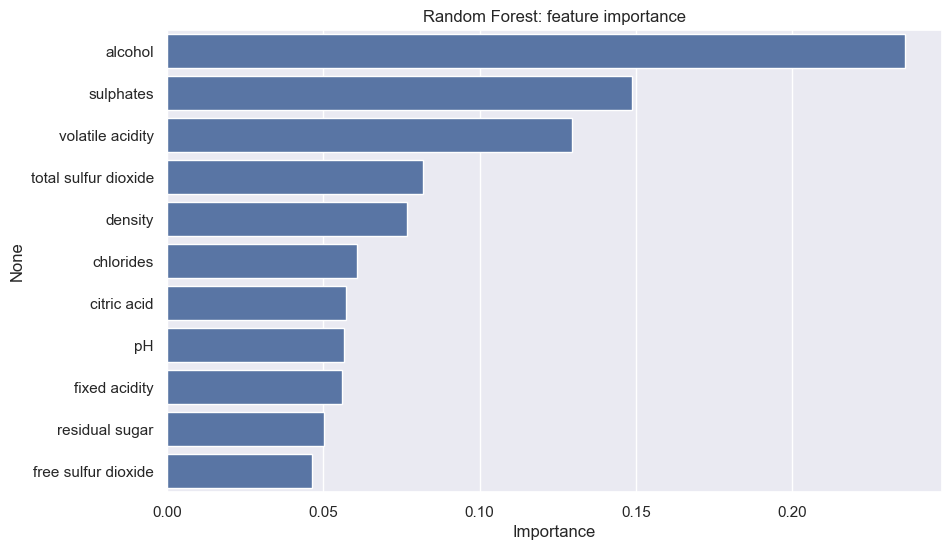

In [26]:
rf_importances = pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)

plot = sns.barplot(y=rf_importances.index, x=rf_importances, color="C0")
plot.figure.set_size_inches(10, 6)
plt.title("Random Forest: feature importance")
plt.xlabel("Importance")

rf_importances.round(3)

`feature_importances_` у случайного леса (impurity-based, MDI) показывает, насколько в сумме уменьшается MSE за счёт разбиений по этому признаку во всех деревьях (нормировано так, что сумма = 1).

Выводы:
- Самый важный признак — `alcohol` (≈0.24), с большим отрывом. Дальше идут `sulphates` (≈0.15) и `volatile acidity` (≈0.13), потом `total sulfur dioxide` (≈0.08). Остальные признаки идут плотной группой (0.05–0.08).
- С EDA это в целом совпадает: алкоголь и летучая кислотность были самыми скоррелированными с качеством. Но у леса `sulphates` важнее летучей кислотности, хотя по корреляции наоборот (0.23 против −0.38). Скорее всего, дело в нелинейности: сульфаты растут с оценкой до 7, а потом выходят на плато, и деревья используют это через пороги лучше, чем линейная корреляция может показать.
- `citric acid` по корреляции был 4-м (0.21), а у леса только 7-й: его информация дублируется летучей кислотностью и сульфатами, с которыми он скоррелирован.
- С линейной регрессией топ-4 совпадает (alcohol, volatile acidity, sulphates, total sulfur dioxide). Отличие — `density`: у LR вес почти нулевой, а у леса она на 5-м месте. В лесу при каждом разбиении доступна только половина признаков (`max_features=0.5`), и когда `alcohol` не попал в это подмножество, дерево берёт его «заместителя» — плотность (r = −0.51 с алкоголем).
- Надо помнить, что MDI считается по train и завышает важность непрерывных признаков с большим числом уникальных значений. Поэтому в части 10 дополнительно проверю важность другим способом.

# Часть 8. Gradient Boosting

Градиентный бустинг строит деревья последовательно: каждое следующее дерево обучается исправлять ошибки уже построенного ансамбля (приближает антиградиент функции потерь, для MSE это просто остатки), и его вклад умножается на `learning_rate`. В отличие от леса, где деревья независимые и усредняются, в бустинге деревья зависят друг от друга, и качество растёт за счёт их количества.

Подбираю через `RandomizedSearchCV` на тех же фолдах:
- `n_estimators` и `learning_rate` связаны: чем меньше шаг, тем больше нужно деревьев (поэтому `learning_rate` беру по логарифмической шкале);
- `max_depth`, `min_samples_leaf` — сложность одного дерева;
- `subsample` — доля объектов для обучения каждого дерева (стохастический бустинг, уменьшает переобучение);
- `max_features` — как у леса.

In [27]:
from sklearn.ensemble import GradientBoostingRegressor
from scipy.stats import uniform

gb_params = {
    "n_estimators": randint(100, 1200),
    "learning_rate": loguniform(0.01, 0.2),
    "max_depth": randint(2, 11),
    "min_samples_leaf": randint(1, 20),
    "subsample": uniform(0.6, 0.4),
    "max_features": [None, "sqrt", 0.5, 0.7],
}

gb_searcher = RandomizedSearchCV(
    GradientBoostingRegressor(random_state=RANDOM_STATE),
    gb_params,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
gb_searcher.fit(X_train, y_train)

print("Best params:", gb_searcher.best_params_)
print("Best CV RMSE = %.4f" % -gb_searcher.best_score_)

Best params: {'learning_rate': np.float64(0.015435211146627065), 'max_depth': 7, 'max_features': 0.7, 'min_samples_leaf': 4, 'n_estimators': 302, 'subsample': np.float64(0.7478617824245618)}
Best CV RMSE = 0.6041


In [28]:
gb_cv_results = pd.DataFrame(gb_searcher.cv_results_)
gb_cv_results["CV RMSE"] = -gb_cv_results["mean_test_score"]
gb_cv_results = gb_cv_results.sort_values("CV RMSE")
gb_cv_results[["param_n_estimators", "param_learning_rate", "param_max_depth", "param_min_samples_leaf", "param_subsample", "param_max_features", "CV RMSE", "std_test_score"]].head(10)

,param_n_estimators,param_learning_rate,param_max_depth,param_min_samples_leaf,param_subsample,param_max_features,CV RMSE,std_test_score
28,302,0.015435,7,4,0.747862,0.7,0.604072,0.033585
1,971,0.011901,9,4,0.883229,None,0.610098,0.039012
14,1151,0.012483,8,9,0.945241,sqrt,0.610691,0.029307
0,221,0.030711,9,7,0.662398,None,0.611107,0.030772
22,289,0.024245,6,12,0.644021,sqrt,0.614973,0.029148
18,306,0.053733,8,9,0.771016,0.5,0.615266,0.030956
12,747,0.016407,10,9,0.602209,0.5,0.615622,0.026951
21,677,0.018373,8,19,0.849742,0.5,0.615698,0.027609
5,341,0.012152,5,14,0.754167,None,0.615955,0.029755
29,983,0.020657,7,5,0.993369,0.7,0.616244,0.029509


In [29]:
gb_model = gb_searcher.best_estimator_
y_pred_gb = gb_model.predict(X_test)

print("Train RMSE = %.4f" % root_mean_squared_error(y_train, gb_model.predict(X_train)))
evaluate("Gradient Boosting", y_test, y_pred_gb, -gb_searcher.best_score_)

Train RMSE = 0.2713
Gradient Boosting: Test RMSE = 0.5693, Test MAE = 0.4256


Вывод:
- Лучшая комбинация: маленький шаг (`learning_rate` ≈ 0.015) и 302 дерева глубины 7, `min_samples_leaf=4`, `subsample` ≈ 0.75, `max_features=0.7`. Маленький шаг — типичный выбор: каждое дерево вносит небольшую поправку, и ансамбль меньше переобучается. Лучшая глубина (7) внутри диапазона поиска (2–10), так что диапазон достаточный.
- CV RMSE = 0.604 — чуть хуже, чем у леса (0.597), а на тесте RMSE = 0.569, MAE = 0.426 — практически так же, как у леса (0.570 и 0.427). Разница между ними и на CV, и на тесте намного меньше разброса по фолдам (std ≈ 0.03), так что по качеству эти две модели не различаются.
- RMSE на train = 0.27 — бустинг, как и лес, сильно подстраивается под обучающие данные.

,Random Forest,Gradient Boosting
alcohol,0.236,0.234
sulphates,0.149,0.141
volatile acidity,0.130,0.129
total sulfur dioxide,0.082,0.089
density,0.077,0.064
chlorides,0.061,0.070
citric acid,0.057,0.054
pH,0.057,0.063
fixed acidity,0.056,0.058
residual sugar,0.050,0.049


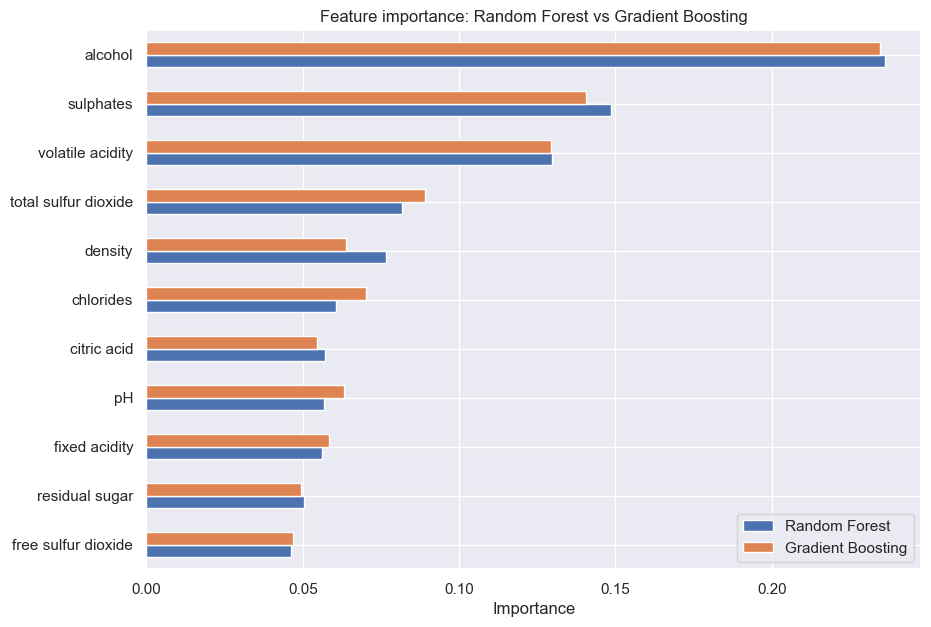

In [30]:
gb_importances = pd.Series(gb_model.feature_importances_, index=X_train.columns)

importances = pd.DataFrame({"Random Forest": rf_importances, "Gradient Boosting": gb_importances}).sort_values("Random Forest")
importances.plot(kind="barh", figsize=(10, 7))
plt.title("Feature importance: Random Forest vs Gradient Boosting")
plt.xlabel("Importance")
plt.legend(loc="lower right")

importances.sort_values("Random Forest", ascending=False).round(3)

Выводы (сравнение RF и GB):
- Важности почти совпадают: у обеих моделей одинаковый топ-4 с почти одинаковыми значениями — `alcohol` (0.236 и 0.234), `sulphates` (0.149 и 0.141), `volatile acidity` (0.130 и 0.129), `total sulfur dioxide` (0.082 и 0.089).
- Различия только в хвосте, где все значения маленькие: у бустинга чуть ниже `density` (0.064 против 0.077) и чуть выше `chlorides` (0.070 против 0.061). Плотность у бустинга менее важна по той же причине, что и раньше: она в основном дублирует алкоголь, а в бустинге каждое следующее дерево исправляет остатки предыдущих, и информацию об алкоголе уже забрали первые деревья.
- Т.е. две разные по устройству модели нашли в данных одно и то же: качество красного вина в первую очередь определяется алкоголем, сульфатами и летучей кислотностью. Это совпадает и с EDA, и с линейной регрессией.

# Часть 9. Честное сравнение моделей

Условия для всех моделей одинаковые:
- одни и те же 11 признаков и одни и те же данные: train и test получены одним разбиением в части 2;
- гиперпараметры подобраны на одних и тех же фолдах `cv`;
- все метрики посчитаны на одном и том же test.

Единственное отличие в обработке — `StandardScaler` внутри пайплайна линейной регрессии. На её предсказания он не влияет и нужен только для интерпретации весов. Деревьям масштабирование не нужно: их предсказания от него не изменились бы.

In [31]:
results_df = pd.DataFrame(results).T
results_df["Лучше baseline"] = results_df["RMSE"] < results_df.loc["Baseline", "RMSE"]
results_df["RMSE < 0.70"] = results_df["RMSE"] < 0.70
results_df.round(4)

,RMSE,MAE,CV RMSE,Лучше baseline,RMSE < 0.70
Baseline,0.8033,0.6812,0.8080,False,False
Linear Regression,0.6375,0.4951,0.6570,True,True
Random Forest,0.5697,0.4271,0.5973,True,True
Gradient Boosting,0.5693,0.4256,0.6041,True,True


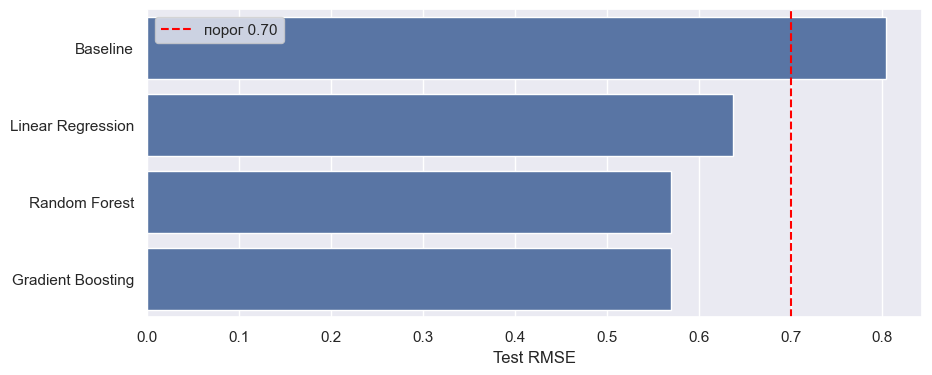

In [32]:
plot = sns.barplot(y=results_df.index, x=results_df["RMSE"], color="C0")
plot.figure.set_size_inches(10, 4)
plt.axvline(0.70, color="red", linestyle="--", label="порог 0.70")
plt.xlabel("Test RMSE")
plt.ylabel("")
plt.legend()

Выводы:
- **Все три модели превзошли baseline** (0.803): линейная регрессия — на 21% (0.638), случайный лес и бустинг — на 29% (0.570 и 0.569). Т.е. модели действительно извлекают информацию из признаков, а не просто выдают среднее.
- **Порог 0.70 проходят все три модели**, включая линейную регрессию.
- Порядок моделей по CV: лес (0.597), бустинг (0.604), линейная регрессия (0.657). На тесте лес и бустинг практически равны. У всех моделей тестовый RMSE немного ниже CV (даже у baseline 0.803 против 0.808): тест из 320 вин получился чуть «проще» среднего. Это ещё одна причина принимать решения по CV, а не по тесту.

Почему так получилось:
- **Linear Regression** хуже моделей на деревьях, потому что недообучена: она может описать только сумму признаков с весами. А в данных, как показал EDA, часть связей нелинейная: у алкоголя излом на оценке 5, у летучей кислотности пороговый эффект, у сульфатов насыщение. Train RMSE ≈ CV RMSE — модели просто не хватает гибкости.
- **Random Forest и Gradient Boosting** состоят из деревьев, которые сами находят пороги и взаимодействия признаков. Поэтому им хватает тех же 11 признаков без ручного feature engineering. Кроме того, деревья умеют «запоминать» конкретные объекты, а в данных много повторов — в части 11 видно, что заметная часть их преимущества приходится именно на вина, у которых есть копия в train.
- **Лес и бустинг одинаковы по качеству**: разница меньше разброса по фолдам (std ≈ 0.03). Лес уменьшает разброс, усредняя независимые глубокие деревья, а бустинг уменьшает смещение, последовательно исправляя ошибки. При маленьком датасете и шумном таргете (оценка эксперта субъективна) оба подхода упираются примерно в один уровень.
- **MAE у всех моделей заметно меньше RMSE** (у леса 0.427 против 0.570): большинство вин предсказывается точно, а RMSE раздувают редкие крупные ошибки. Это разберу в анализе ошибок.

# Часть 10. Feature importance: сравнение моделей

Сравнивать напрямую веса линейной регрессии и `feature_importances_` деревьев некорректно — это разные величины. К тому же impurity-based importance у деревьев считается по train и завышает важность признаков с большим числом уникальных значений.

Поэтому для всех трёх моделей дополнительно посчитаю **permutation importance**: случайно перемешиваю значения одного признака в тестовой выборке и смотрю, насколько вырастет RMSE. Чем сильнее растёт ошибка, тем больше модель полагается на этот признак. Это одна и та же величина (прирост RMSE в баллах) для любой модели, поэтому модели можно сравнивать между собой. Считаю на тесте, потому что модели уже обучены и зафиксированы, и по этим результатам ничего не выбирается — это только интерпретация.

Text(0.5, 0, 'Прирост RMSE')

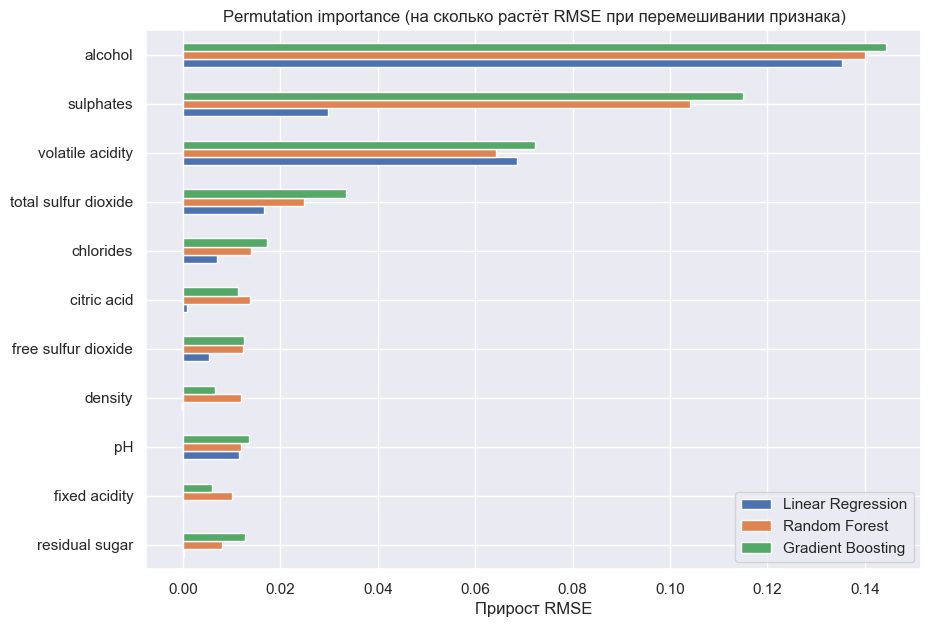

In [33]:
from sklearn.inspection import permutation_importance

models = {"Linear Regression": linear_pipeline, "Random Forest": rf_model, "Gradient Boosting": gb_model}

perm_importances = {}
for name, model in models.items():
    perm = permutation_importance(model, X_test, y_test, scoring="neg_root_mean_squared_error", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
    perm_importances[name] = pd.Series(perm.importances_mean, index=X_test.columns)

perm_importances = pd.DataFrame(perm_importances).sort_values("Random Forest")
perm_importances.plot(kind="barh", figsize=(10, 7))
plt.title("Permutation importance (на сколько растёт RMSE при перемешивании признака)")
plt.xlabel("Прирост RMSE")

In [34]:
ranks = pd.DataFrame({
    "|corr| с quality": X_train.corrwith(y_train).abs(),
    "|вес| LR": coefs["|вес после масштабирования|"],
    "RF importance": rf_importances,
    "GB importance": gb_importances,
    "perm LR": perm_importances["Linear Regression"],
    "perm RF": perm_importances["Random Forest"],
    "perm GB": perm_importances["Gradient Boosting"],
}).rank(ascending=False).astype(int)
ranks.sort_values("perm RF")

,|corr| с quality,|вес| LR,RF importance,GB importance,perm LR,perm RF,perm GB
alcohol,1,1,1,1,1,1,1
sulphates,3,3,2,2,3,2,2
volatile acidity,2,2,3,3,2,3,3
total sulfur dioxide,5,4,4,4,4,4,4
chlorides,7,6,6,5,6,5,5
citric acid,4,8,7,9,8,6,9
free sulfur dioxide,10,7,11,11,7,7,8
density,6,9,5,6,11,8,10
pH,9,5,8,7,5,9,6
fixed acidity,8,11,9,8,10,10,11


Выводы:
- **Все три модели согласны между собой**: по permutation importance у всех трёх одна и та же четвёрка главных признаков — `alcohol`, `sulphates`, `volatile acidity`, `total sulfur dioxide`. Алкоголь с большим отрывом самый важный: если его перемешать, RMSE вырастает на ~0.14 балла у всех трёх моделей.
- **Главное различие — `sulphates`**: для деревьев перемешивание сульфатов увеличивает RMSE на ~0.10–0.11, а для линейной регрессии только на ~0.03. Это подтверждает вывод из EDA, что связь сульфатов с качеством нелинейная (рост и потом плато), и линейная модель использует её гораздо хуже. Скорее всего, это одна из главных причин, почему деревья точнее.
- Остальные признаки для всех моделей второстепенные (прирост RMSE < 0.02). У линейной регрессии `density`, `citric acid`, `fixed acidity` и `residual sugar` вообще почти не важны — их информация есть в других признаках.
- **Сравнение с EDA**: признаки с самой сильной корреляцией (алкоголь, летучая кислотность, сульфаты) — главные и для всех моделей. А вот `citric acid` и `density`, которые по корреляции были на 4-м и 6-м местах, для моделей оказались второстепенными: их связь с качеством идёт в основном «через» другие признаки (летучую кислотность и алкоголь). MDI и permutation importance у деревьев в целом совпадают, но MDI сильнее «размазан» по признакам и завышает `density`.

**Можно ли на основании feature importance утверждать, что изменение признака является причиной изменения качества вина?**

Нет. Feature importance показывает только то, насколько **модель** использует признак для предсказания, т.е. насколько он статистически связан с оценкой в этих данных. Причинность из этого не следует:
1. **Данные наблюдательные**, а не экспериментальные: никто не менял один признак при фиксированных остальных. Мы видим только, что крепкие вина в среднем получают более высокие оценки.
2. **Есть скрытые общие причины (конфаундеры)**: сорт винограда, погода, зрелость ягод, технология производства влияют одновременно и на химический состав, и на качество. Например, высокий алкоголь — признак спелого винограда и правильного брожения. Если в плохое вино просто долить спирт, лучше оно не станет. Сульфаты добавляют при производстве как консервант, и их связь с качеством может отражать то, как аккуратно работает винодельня, а не прямое влияние на вкус.
3. **Скоррелированные признаки подменяют друг друга**: `density` выглядит важной для леса, но это в основном «заместитель» алкоголя, а `citric acid` важен по корреляции, но не для моделей. Важность признака зависит от того, какие ещё признаки есть в модели.
4. **Важность зависит от модели и способа подсчёта**: LR, RF и GB, MDI и permutation importance дают разные значения на одних и тех же данных (например, у сульфатов). Настоящий причинный эффект от выбора модели не зависел бы.
5. Важность ничего не говорит о **направлении** влияния и о том, при каких значениях признак работает.

Чтобы говорить о причинности, нужен эксперимент (например, менять один параметр при производстве и сравнивать слепые оценки) или специальные методы причинного вывода с явными предположениями.

# Часть 11. Анализ ошибок лучшей модели

Лучшую модель выбираю по CV RMSE (а не по тесту).

In [35]:
best_name = results_df.drop(index="Baseline")["CV RMSE"].astype(float).idxmin()
best_model = models[best_name]
print("Лучшая модель по CV:", best_name)

errors = pd.DataFrame({"true": y_test, "pred": best_model.predict(X_test)})
errors["error"] = errors["pred"] - errors["true"]
errors["abs_error"] = errors["error"].abs()

print("Средняя ошибка (смещение) = %.4f" % errors["error"].mean())
print("Доля объектов с |ошибкой| < 0.5: %.3f" % (errors["abs_error"] < 0.5).mean())
print("Доля объектов с |ошибкой| > 1: %.3f" % (errors["abs_error"] > 1).mean())
print("Доля объектов с |ошибкой| > 2: %.3f" % (errors["abs_error"] > 2).mean())

Лучшая модель по CV: Random Forest
Средняя ошибка (смещение) = 0.0351
Доля объектов с |ошибкой| < 0.5: 0.659
Доля объектов с |ошибкой| > 1: 0.081
Доля объектов с |ошибкой| > 2: 0.006


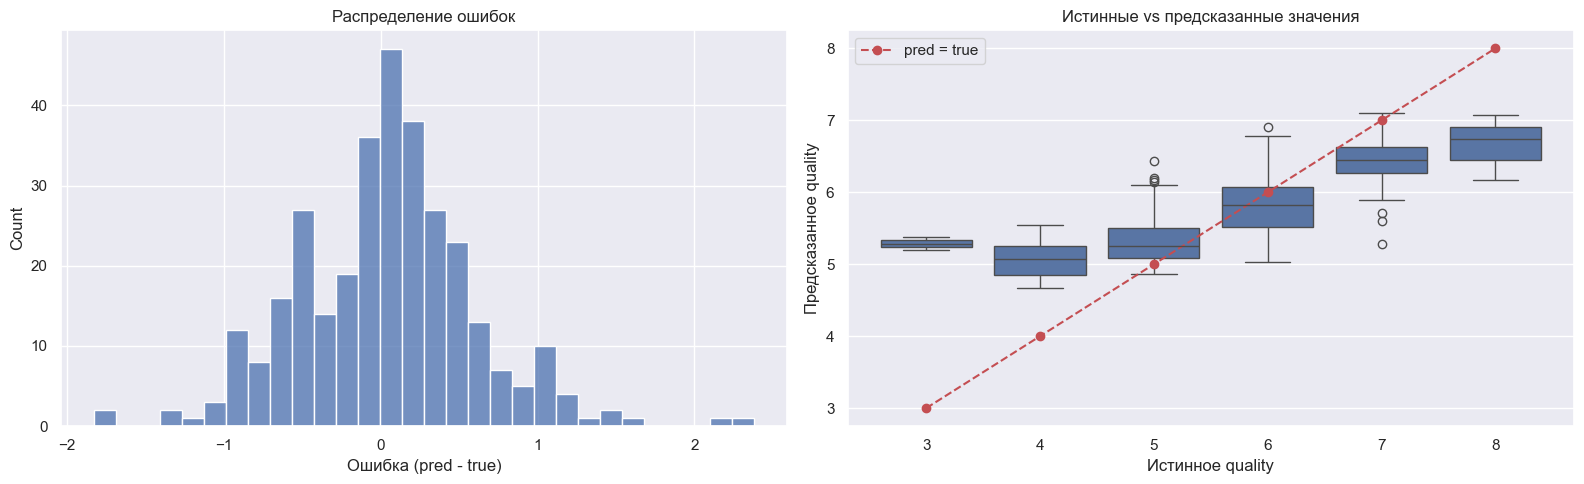

In [36]:
qualities = sorted(errors["true"].unique())

fig, axs = plt.subplots(figsize=(16, 5), ncols=2)
sns.histplot(errors["error"], bins=30, ax=axs[0])
axs[0].set_xlabel("Ошибка (pred - true)")
axs[0].set_title("Распределение ошибок")

sns.boxplot(data=errors, x="true", y="pred", color="C0", ax=axs[1])
axs[1].plot(range(len(qualities)), qualities, "r--o", label="pred = true")
axs[1].set_xlabel("Истинное quality")
axs[1].set_ylabel("Предсказанное quality")
axs[1].set_title("Истинные vs предсказанные значения")
axs[1].legend()
plt.tight_layout()

In [37]:
by_quality = errors.groupby("true").agg(
    count=("error", "size"),
    mean_pred=("pred", "mean"),
    mean_error=("error", "mean"),
    MAE=("abs_error", "mean"),
    RMSE=("error", lambda e: np.sqrt(np.mean(e ** 2))),
)
by_quality.round(3)

,count,mean_pred,mean_error,MAE,RMSE
true,,,,,
3,2,5.287,2.287,2.287,2.289
4,11,5.072,1.072,1.072,1.107
5,136,5.340,0.340,0.352,0.471
6,128,5.816,-0.184,0.347,0.433
7,40,6.403,-0.597,0.602,0.707
8,3,6.660,-1.340,1.340,1.390


Выводы:
- Ошибки распределены примерно симметрично вокруг нуля, смещения почти нет (средняя ошибка 0.035). У 66% вин ошибка меньше полбалла, т.е. после округления они получили бы правильную оценку. Ошибка больше 1 балла — у 8% вин, больше 2 баллов — только у двух вин из 320.
- Но для разных оценок модель работает **неодинаково**. Для самых частых оценок 5 и 6 ошибка небольшая (RMSE 0.47 и 0.43), для 7 — уже 0.71, для 4 — 1.11, для 8 — 1.39, для 3 — больше 2. Правда, вин с оценками 3 и 8 в тесте всего 2 и 3, так что цифры для них очень приблизительные, но тенденция понятная.
- Видна **систематическая «тяга к центру»**: плохие вина модель переоценивает (для оценки 3 предсказывает в среднем 5.29, для 4 — 5.07), а хорошие недооценивает (для 7 в среднем 6.40, для 8 — 6.66). На графике справа медианы предсказаний лежат на более пологой линии, чем идеальная диагональ.
- Именно поэтому RMSE (0.57) заметно больше MAE (0.43): крупные ошибки сосредоточены на немногочисленных крайних винах.

**Почему модель хуже предсказывает редкие значения quality:**
1. **Мало примеров.** Вин с оценкой 3 в train всего 8, с оценкой 8 — 15, а с оценками 5–6 больше тысячи. Модель минимизирует среднюю ошибку по всем объектам, и ей выгоднее хорошо предсказывать массовые вина, чем подстраиваться под единичные.
2. **Деревья усредняют.** Предсказание дерева — среднее таргета в листе. Редкое вино попадает в лист вместе с похожими по химии винами, у которых оценки 5–6, и среднее сдвигается к центру.
3. **Плохие и отличные вина часто химически не отличаются от средних.** Оценка — субъективное мнение экспертов, в ней есть шум, а часть того, что влияет на оценку (аромат, вкус, баланс), в 11 измерениях не отражена.
4. **Регрессия с MSE в принципе тянет к условному среднему**: если по признакам вино похоже и на «пятёрку», и на «тройку», то оптимальный с точки зрения MSE ответ — где-то посередине, ближе к более частой оценке.

In [38]:
worst = errors.sort_values("abs_error", ascending=False).head(10)
X_test.loc[worst.index].join(worst[["true", "pred", "error"]]).round(3)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,true,pred,error
832,10.4,0.440,0.42,1.5,0.145,34.0,48.0,0.998,3.38,0.86,9.9,3,5.381,2.381
1374,6.8,0.815,0.00,1.2,0.267,16.0,29.0,0.995,3.32,0.51,9.8,3,5.194,2.194
440,12.6,0.310,0.72,2.2,0.072,6.0,29.0,0.999,2.88,0.82,9.8,8,6.170,-1.830
943,9.8,0.500,0.34,2.3,0.094,10.0,45.0,0.999,3.24,0.60,9.7,7,5.288,-1.712
703,7.5,0.380,0.48,2.6,0.073,22.0,84.0,0.997,3.32,0.70,9.6,4,5.541,1.541
1233,10.2,0.230,0.37,2.2,0.057,14.0,36.0,0.996,3.23,0.49,9.3,4,5.454,1.454
1322,9.1,0.340,0.42,1.8,0.058,9.0,18.0,0.994,3.18,0.55,11.4,5,6.431,1.431
442,15.6,0.685,0.76,3.7,0.100,6.0,43.0,1.003,2.95,0.68,11.2,7,5.606,-1.394
1482,7.2,0.580,0.54,2.1,0.114,3.0,9.0,0.997,3.33,0.57,10.3,4,5.339,1.339
230,5.2,0.480,0.04,1.6,0.054,19.0,106.0,0.993,3.54,0.62,12.2,7,5.713,-1.287


In [39]:
# типичные значения ключевых признаков для каждой оценки (по train), чтобы было с чем сравнивать
train.groupby("quality")[["alcohol", "volatile acidity", "sulphates", "citric acid", "chlorides", "total sulfur dioxide"]].median().round(3)

,alcohol,volatile acidity,sulphates,citric acid,chlorides,total sulfur dioxide
quality,,,,,,
3,10.075,0.928,0.545,0.035,0.083,14.0
4,10.050,0.653,0.560,0.085,0.080,29.0
5,9.600,0.580,0.580,0.230,0.082,50.0
6,10.575,0.500,0.640,0.270,0.078,36.0
7,11.400,0.360,0.740,0.400,0.073,26.0
8,12.500,0.400,0.740,0.340,0.070,24.0


Разберу несколько вин с самыми большими ошибками (сравниваю с медианами признаков для их оценки из таблицы выше):
- **№832** (реальная оценка 3, предсказано 5.38). Летучая кислотность 0.44 — даже ниже, чем у типичной «пятёрки» (0.58), а у вин на 3 медиана 0.93. Сульфаты (0.86) и лимонная кислота (0.42) — как у хороших вин. Повышены только хлориды (0.145). По главным признакам это нормальное вино, и почему эксперты поставили 3, из химии не видно: скорее всего, дефект, которого нет в признаках, или шум в оценке.
- **№1374** (оценка 3, предсказано 5.19). Здесь модель правильно увидела проблему: высокая летучая кислотность (0.815), очень много хлоридов (0.267, в 3 раза выше типичного), нет лимонной кислоты, мало сульфатов. Предсказание ниже среднего, но до 3 модель не дотягивает: вин с оценкой 3 в train всего 8, и в листьях деревьев они усредняются с винами на 5.
- **№440** (оценка 8, предсказано 6.17). Смешанные сигналы: сульфаты (0.82), лимонная кислота (0.72) и низкая летучая кислотность (0.31) — как у лучших вин, но алкоголь всего 9.8 (у вин на 8 медиана 12.5). Главный для модели признак говорит «среднее вино», и она останавливается на 6.
- **№943** (оценка 7, предсказано 5.29). Алкоголь 9.7, сульфаты 0.60, летучая кислотность 0.50 — по всем главным признакам это типичная «пятёрка». За что эксперты дали 7, в данных не видно.
- **№230** (оценка 7, предсказано 5.71). Алкоголь высокий (12.2), но общий диоксид серы 106 — в 4 раза выше, чем обычно у вин на 7 (медиана 26), а сульфаты невысокие (0.62). Модель знает, что много SO₂ — это плохо, и сильно снижает предсказание.

Общая картина: крупные ошибки — это либо редкие крайние оценки, до которых модель «не дотягивается» из-за усреднения, либо вина, у которых химический профиль типичен для другой оценки (тогда причина вне признаков или в субъективности оценки).

Отдельно проверю, насколько на оценку влияют повторы, найденные в начале: посчитаю ошибку отдельно для тестовых вин, у которых есть точная копия (по признакам) в train, и для остальных. Для сравнения — для всех трёх моделей.

In [40]:
train_rows = set(map(tuple, X_train.values))
has_copy = np.array([tuple(row) in train_rows for row in X_test.values])
print("Тестовых вин, у которых есть копия в train: %d (доля %.3f)" % (has_copy.sum(), has_copy.mean()))

copy_check = {}
for name, model in models.items():
    y_pred = model.predict(X_test)
    copy_check[name] = {
        "RMSE (весь test)": root_mean_squared_error(y_test, y_pred),
        "RMSE (есть копия в train)": root_mean_squared_error(y_test[has_copy], y_pred[has_copy]) if has_copy.sum() > 0 else np.nan,
        "RMSE (нет копии в train)": root_mean_squared_error(y_test[~has_copy], y_pred[~has_copy]),
    }
pd.DataFrame(copy_check).T.round(4)

Тестовых вин, у которых есть копия в train: 76 (доля 0.237)


,RMSE (весь test),RMSE (есть копия в train),RMSE (нет копии в train)
Linear Regression,0.6375,0.5990,0.6490
Random Forest,0.5697,0.2886,0.6323
Gradient Boosting,0.5693,0.2646,0.6350


Это важный результат:
- У 76 тестовых вин (24%) есть точная копия в train (это те самые дубликаты из части 1).
- На таких винах лес и бустинг почти не ошибаются (RMSE 0.29 и 0.26): они фактически вспоминают оценку копии. Линейная регрессия запоминать не умеет, и у неё разница между копиями и остальными винами небольшая (0.60 против 0.65, на 76 винах это в пределах случайности).
- На винах **без копии** в train RMSE у всех трёх моделей почти одинаковый: 0.632 у леса, 0.635 у бустинга и 0.649 у линейной регрессии. Это честная оценка качества на действительно новых винах. Порог 0.70 проходят все три модели.
- Получается, что большая часть преимущества деревьев в итоговой таблице (0.570 против 0.638) набирается на копиях. На новых винах деревья лучше линейной регрессии всего на ~0.015.

Итого: общий тестовый RMSE корректен для выборки, устроенной как исходный датасет (с повторами), но для новых, ранее не встречавшихся вин надо ориентироваться на ~0.63–0.65. Это же объясняет, почему подбор гиперпараметров выбрал маленькие листья: в кросс-валидации повторы тоже попадают в разные фолды, и запоминать выгодно. Если запустить ноутбук без дубликатов (строка в части 1), этого эффекта не будет, и качество будет ближе к последней колонке.

# Итоги

| Модель | RMSE | MAE |
|---|---|---|
| Baseline (среднее по train) | 0.803 | 0.681 |
| Linear Regression | 0.638 | 0.495 |
| Random Forest | 0.570 | 0.427 |
| Gradient Boosting | 0.569 | 0.426 |

- Использованы только красные вина (1599 объектов, 11 признаков). Разбиение 80/20 со стратификацией по `quality`, `random_state=42`. Все решения приняты по 5-fold CV на train, гиперпараметры подобраны случайным поиском (`RandomizedSearchCV`), тест использован только для финальной оценки.
- Все модели лучше baseline, и все проходят порог RMSE < 0.70. Лучшая модель по CV — Random Forest (CV RMSE = 0.597, на тесте RMSE = 0.570, MAE = 0.427). Gradient Boosting на тесте практически такой же, разница между ними в пределах шума.
- Линейная регрессия недообучена: часть зависимостей нелинейная (алкоголь, летучая кислотность, сульфаты), а деревья находят их сами.
- Самые важные признаки у всех моделей — `alcohol`, `sulphates` и `volatile acidity`, что совпадает с EDA. Но важность признаков не означает причинную связь.
- Хуже всего модели предсказывают редкие оценки (3–4 и 8) и тянут предсказания к центру.
- У 24% тестовых вин есть копия в train, и на них модели на деревьях почти не ошибаются. На новых винах честный RMSE ≈ 0.63 у деревьев и 0.65 у линейной регрессии — все модели всё равно ниже порога.